# データサイエンス実践A 第15講：時系列
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月27日（金）**

1. 日付の列を**日付の型**にして、**時系列**（時間の流れに沿ったデータ）のグラフを描く。期間の絞り方と、e-Stat の統計ダッシュボードから取った実データでの描き方、よくあるトラブルの直し方を確かめる。
1. 移動平均・日付の目盛は発展。できる人だけ。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AQ. 時系列](#AQ.-時系列)**
- [AQ-0 今日の完成形](#AQ-0-今日の完成形)
- [AQ-1 日付の列を日付の型にする](#AQ-1-日付の列を日付の型にする)
- [AQ-2 時系列のグラフを描く](#AQ-2-時系列のグラフを描く)
- [AQ-3 期間を絞る](#AQ-3-期間を絞る)
- [AQ-4 実データで、取るところから時系列のグラフまで](#AQ-4-実データで、取るところから時系列のグラフまで)
- [AQ-5 日付の引き算と、今の日時（時間があれば）](#AQ-5-日付の引き算と、今の日時（時間があれば）)
- [AQ-6 よくあるトラブル](#AQ-6-よくあるトラブル)
- [参考：ネット記事でよく見る datetime の書き方](#参考：ネット記事でよく見る-datetime-の書き方)

**[AS. 発展（できる人だけ）](#AS.-発展（できる人だけ）)**
- [AS-1 移動平均](#AS-1-移動平均)
- [AS-2 日付の目盛の書き方を決める](#AS-2-日付の目盛の書き方を決める)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は、e-Stat などのデータを **Excel で整えて**読む手順（第14講 AN）と、**回帰**を学んだ
- `res = ols('y の列名 ~ x の列名', data=df).fit()` で、散布図にいちばん合う直線を求めた
- 傾きは「x が 1 増えると y がどれだけ増えるか」、決定係数は直線の合い具合（0〜1）
- 今日は、横軸が日付の**時系列**のグラフを学ぶ

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

---
# AQ. 時系列

**時系列**は、横軸が時間（日付）のグラフ。これまで扱ったデータの型は、整数（`int`）・小数（`float`）・文字（`str`）だった。日付には、これらとは別に専用の**日付の型**（pandas では `datetime64`）がある。日付の型にすると、横軸が日付の間隔どおりに並び、期間で絞ったり、日付の引き算をしたりできる。AQ では、この日付の型の扱いを学ぶ。使う道具は次のとおり。

| 書き方 | 働き | 学ぶところ |
|---|---|---|
| `pd.to_datetime(df['Date'])` | 列をまとめて日付の型にする。読んだ表の日付の列が文字（`object`）のときに使う | AQ-1 |
| `pd.Timestamp('2008-09-15')` | 日付を1つ作る。`axvline` で線を引く位置や、`plt.xlim` の期間の始まり・終わりに使う | AQ-0・AQ-3 |
| `df[df['Date'] >= '2020-01-01']` | 日付で行を絞る。日付の型の列は、`'2020-01-01'` の形の文字と比べられる | AQ-3 |
| `(日付 - 日付).days`、`pd.Timedelta(days=100)` | 日付の引き算（何日離れているか）と、100日後の日付 | AQ-5 |
| `datetime.now()`、`datetime.today()` | 今の日時。`.hour` などで取り出して、if 文の条件に使える（Python の datetime の機能） | AQ-5 |

## AQ-0 今日の完成形

ダウ平均株価（アメリカの代表的な株価の指標）の、2000年以降の週ごとの終値。リーマンショック（2008年）とコロナショック（2020年）に線を引いている。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**期間や線の位置を変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[3]）の働きを1つずつ学ぶ（AQ-1〜AQ-3）

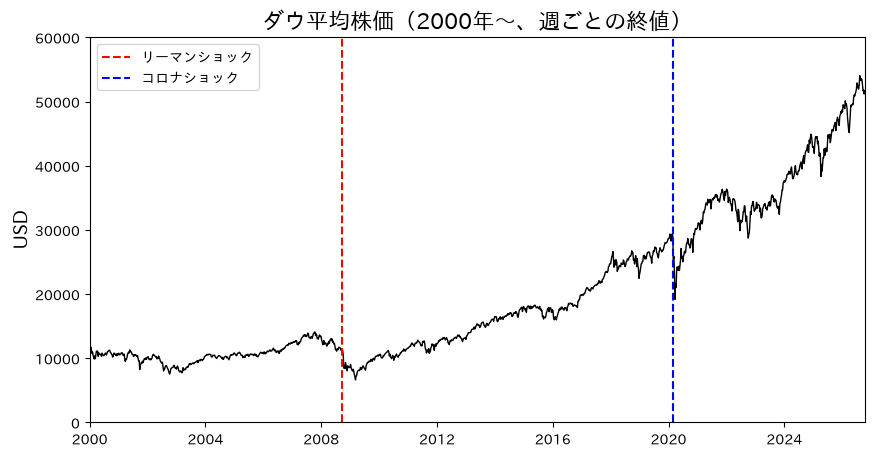

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df_dji = pd.read_excel('dsa2026data.xlsx', sheet_name='dji')
df_dji['Date'] = pd.to_datetime(df_dji['Date'])  # [1] 日付の型にする

plt.figure(figsize=(10, 5))
plt.plot(df_dji['Date'], df_dji['Close'], color='k', linewidth=1)  # [2] 時系列
plt.axvline(x=pd.Timestamp('2008-09-15'), color='r', linestyle='--', label='リーマンショック')  # [3] 日付の位置
plt.axvline(x=pd.Timestamp('2020-03-01'), color='b', linestyle='--', label='コロナショック')  # [3] 日付の位置
plt.xlim(pd.Timestamp('2000-01-01'), df_dji['Date'].max())  # [3] 期間
plt.ylim(0, 60000)
plt.title('ダウ平均株価（2000年〜、週ごとの終値）', fontsize=16)
plt.ylabel('USD', fontsize=14)
plt.legend()
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `'2000-01-01'` → `'2018-01-01'`（期間を短くする。`plt.ylim` も `(15000, 60000)` などに）
- `'Close'` → `'High'`（週の最高値）
- `axvline` の日付を、自分の誕生日や入学した日に変える

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 日付の型にする | `df['Date'] = pd.to_datetime(df['Date'])` | AQ-1 |
| [2] | 時系列のグラフ | `plt.plot(df['Date'], df['Close'])` | AQ-2 |
| [3] | 日付で位置・期間を指定 | `pd.Timestamp('2008-09-15')` | AQ-3 |

In [3]:
# 上のコードを貼り付けて、値を変えてみよう

## AQ-1 日付の列を日付の型にする

Excel や CSV などの外部データを読み込んだとき、日付の列は日付の型になっているとは限らない。文字（`object`）や数字（`int64`）のままのことがあり、そのときは日付の型への**変換が必要**。読んだらまず `df.info()` で列の型を確かめ、`datetime64` でなければ変換する（文字のときは、下の `pd.to_datetime` で変換する。数字のときは AQ-4）。

- `dji` シートは、1896年から2026年10月までの週ごとのダウ平均株価（6783行）
- 出典：[Stooq](https://stooq.com/)（2025年9月まで）、[MarketWatch](https://www.marketwatch.com/investing/index/djia/download-data)（2025年10月から）
- 列：`Date`（日付）、`Open`（始値）、`High`（高値）、`Low`（安値）、`Close`（終値）

In [4]:
df_dji = pd.read_excel('dsa2026data.xlsx', sheet_name='dji')
df_dji.info()
df_dji.head()

<class 'pandas.DataFrame'>
RangeIndex: 6783 entries, 0 to 6782
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    6783 non-null   object 
 1   Open    6783 non-null   float64
 2   High    6783 non-null   float64
 3   Low     6783 non-null   float64
 4   Close   6783 non-null   float64
dtypes: float64(4), object(1)
memory usage: 265.1+ KB


,Date,Open,High,Low,Close
0,1896-05-31,29.39,29.43,29.11,29.43
1,1896-06-07,29.40,29.40,28.80,29.20
2,1896-06-14,28.83,28.83,27.82,28.47
3,1896-06-21,28.92,29.36,28.80,28.99
4,1896-06-28,28.05,28.05,27.44,27.44


- `Date` の型が `object`（文字）になっている。このままだと、横軸に日付が**文字として**並ぶ（間隔や順番が正しくならない）
- `pd.to_datetime(df['列名'])` で**日付の型**（`datetime64`）にする

In [5]:
df_dji['Date'] = pd.to_datetime(df_dji['Date'])
df_dji.info()

<class 'pandas.DataFrame'>
RangeIndex: 6783 entries, 0 to 6782
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    6783 non-null   datetime64[us]
 1   Open    6783 non-null   float64       
 2   High    6783 non-null   float64       
 3   Low     6783 non-null   float64       
 4   Close   6783 non-null   float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 265.1 KB


- `Date` が `datetime64` になった（`datetime64[us]` のように `[ ]` が付くが、中は気にしなくてよい）。これで横軸が年月日として正しく並ぶ
- Excel で日付に見えていても、読み込むと文字になることがある。**時系列では、読んだらまず `info()` で日付の列の型を確かめ、`object`（文字）なら `to_datetime` する**と覚える
- 5けたの数字（`int64`）のときは `to_datetime` しない（エラーは出ずに、1970年のおかしな日付になる）。Excel で直す（AQ-4）

▶ **演習**：`ts_描画基礎001`

## AQ-2 時系列のグラフを描く

- 横軸を日付の列にして、折れ線グラフ（第３講）で描く。点が多いので `marker` は付けない

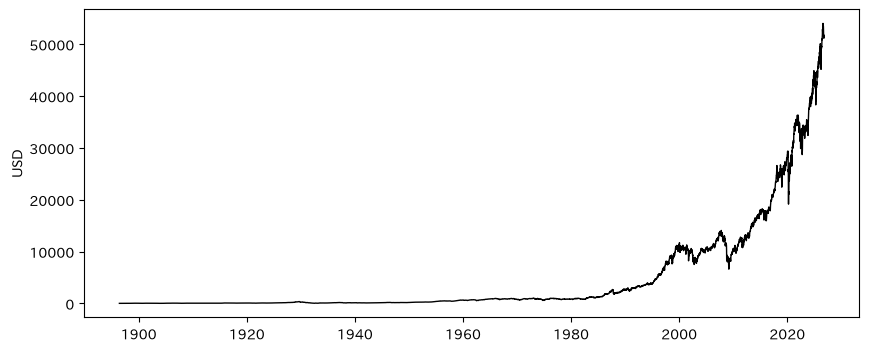

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(df_dji['Date'], df_dji['Close'], color='k', linewidth=1)
plt.ylabel('USD')
plt.show()

- 1990年代より前は、値が小さすぎてほとんど0に見える
- `plt.yscale('log')`（対数目盛、第８講）にすると、10倍ごとに同じ間隔になり、昔の動きも見える

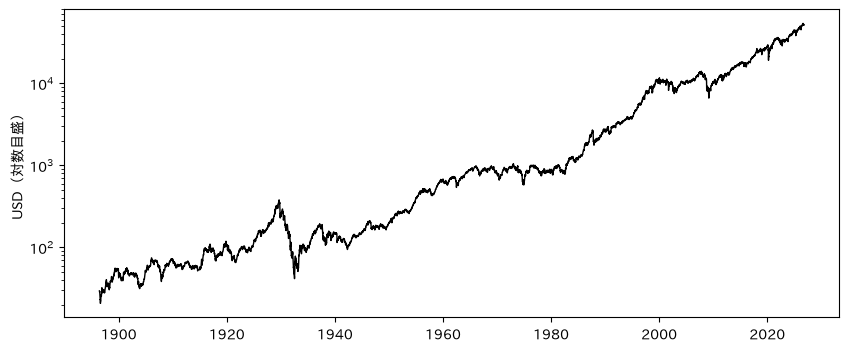

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(df_dji['Date'], df_dji['Close'], color='k', linewidth=1)
plt.yscale('log')
plt.ylabel('USD（対数目盛）')
plt.show()

- 1929年の世界恐慌の大きな下落が見える

## AQ-3 期間を絞る

- 日付は `pd.Timestamp('年-月-日')` で書く。`plt.xlim` や `plt.axvline` の位置に使える
- グラフの表示範囲だけでなく、**データそのものを絞る**こともできる：`df[df['Date'] >= '2020-01-01']`（条件に合う行だけ）
- 使い分け：表の日付の列と**比べるとき**は `'2020-01-01'` の文字のままでよい。`axvline`・`xlim` で**位置を決めるとき**は `pd.Timestamp('2020-01-01')` で日付を作る

354 週


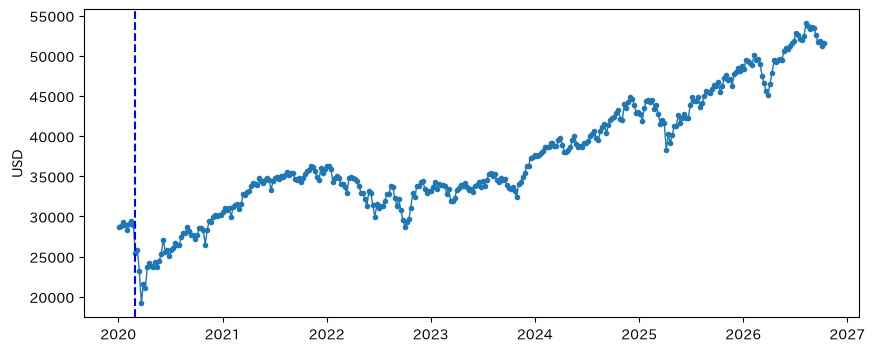

In [8]:
df_recent = df_dji[df_dji['Date'] >= '2020-01-01']
print(len(df_recent), '週')

plt.figure(figsize=(10, 4))
plt.plot(df_recent['Date'], df_recent['Close'], marker='.', linewidth=1)
plt.axvline(x=pd.Timestamp('2020-03-01'), color='b', linestyle='--')
plt.ylabel('USD')
plt.show()

- `df[条件]` は、条件に合う行だけを取り出す書き方。`df_tip[df_tip['day'] == 'Sat']` なら土曜日の行だけ
- 年だけの列（`accident` シートの `年` など）は数字のままでよい。`to_datetime` が要るのは「2020-03-01」のような**年月日**の列

▶ **演習**：`ts_描画基礎002`（出来事の日付に縦線）、`ts_描画基礎003`

### 2つの条件で期間を絞る

- 「2008年から2009年まで」のように、**始まりと終わりの両方**を決めて絞るときは、条件を2つ作って `&`（かつ）でつなぐ
- `cond1 & cond2` は「cond1 と cond2 の**両方**に当てはまる行」。どちらか片方でよいときは `|`（または）

104 週


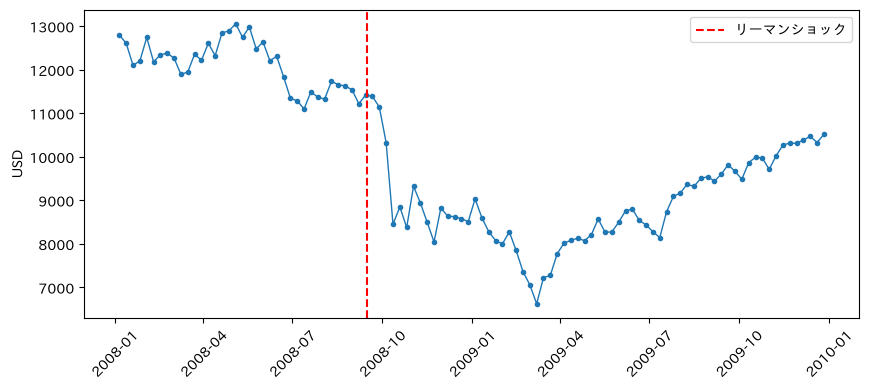

In [9]:
cond1 = df_dji['Date'] >= '2008-01-01'   # [1] 2008年1月1日から
cond2 = df_dji['Date'] < '2010-01-01'    # [2] 2010年1月1日より前
df_lehman = df_dji[cond1 & cond2]        # [3] 両方に当てはまる行
print(len(df_lehman), '週')

plt.figure(figsize=(10, 4))
plt.plot(df_lehman['Date'], df_lehman['Close'], marker='.', linewidth=1)
plt.axvline(x=pd.Timestamp('2008-09-15'), color='r', linestyle='--', label='リーマンショック')
plt.xticks(rotation=45)   # 目盛の文字を斜めにして、重ならないようにする
plt.ylabel('USD')
plt.legend()
plt.show()


- 1行で書くときは、条件をそれぞれ**かっこで囲む**：`df_dji[(df_dji['Date'] >= '2008-01-01') & (df_dji['Date'] < '2010-01-01')]`
- かっこを付けないとエラーになる。`&` の代わりに `and` と書いてもエラーになる（AQ-6）
- 横軸の日付の文字が重なるときは `plt.xticks(rotation=45)` で斜めにする

▶ **演習**：`ts_描画基礎004`

## AQ-4 実データで、取るところから時系列のグラフまで

第14講 AN では、e-Stat から都道府県のデータを取って回帰した。ここでは、**統計ダッシュボード**から月ごとのデータを取り、整える → 読んで確かめる → 折れ線グラフ → 言葉で説明、までを一通りやる。

### 例：有効求人倍率（全国、月ごと）

- **有効求人倍率**：仕事を探している人1人あたりの求人の数。1 より大きければ人手が足りない、1 より小さければ仕事が足りない
- **季節調整値**：毎年同じ時期に起きる増減（年度の変わり目など）を取り除いた値。月ごとの動きを比べやすい

**[1] ページを開く**
- [統計ダッシュボード](https://dashboard.e-stat.go.jp/) の「時系列表」→ 分野で「労働・賃金」→「（季節調整値）有効求人倍率」
- 直接開くなら https://dashboard.e-stat.go.jp/timeSeriesResult?indicatorCode=0301020001000010010

**[2] ダウンロードする**
- 地域で［全国］を押し、［ダウンロード］を押すと CSV が保存される
- 列は `時点`（`1963年1月` 〜）・`地域コード`・`地域`・`（季節調整値）有効求人倍率【倍】`・`注記`。見出しは1行だけ

**[3] Excel で整える**
1. CSV を Excel で開く。`時点` は、Excel が日付として読み、`1963年1月` の形で表示される（列の幅が狭いと `#######`。列の境目をダブルクリックすると広がる）
1. `地域コード`・`地域`・`注記` の列を消す
1. 列名 `（季節調整値）有効求人倍率【倍】` を `有効求人倍率` に直す（かっこや記号のない、短い名前にしておくと扱いやすい）
1. ［名前を付けて保存］で、ファイルの種類を「Excel ブック（*.xlsx）」にして、`有効求人倍率.xlsx` の名前でいつもの場所に保存する

**[4] 読んで確かめる**
- 第14講 AN-2 と同じく、読んだらまず `info()` で確かめる
- 配布の `有効求人倍率.xlsx` では、[3] まで整えた状態をシート `直す前` に入れてある

In [10]:
df_job = pd.read_excel('有効求人倍率.xlsx', sheet_name='直す前')
df_job.info()   # [1]
df_job.head()   # [2]

<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   時点      765 non-null    int64  
 1   有効求人倍率  765 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 12.1 KB


,時点,有効求人倍率
0,23012,0.56
1,23043,0.60
2,23071,0.64
3,23102,0.68
4,23132,0.71


- [1] `有効求人倍率` は `float64` で、数値として読めている。ところが `時点` は **`int64`**（整数）
- [2] `時点` が `23012` のような5けたの数字になっている。Excel の画面では `1963年1月` と見えていたのに、日付として読めていない
- Excel の日付の中身は、1900年1月1日を 1 とした日数（**シリアル値**）。表示の形が `1963年1月` のときは、`read_excel` が日付だと気づかず、中身の数字のまま読む（AQ-6）
- Python で直そうとせず、Excel に戻って表示の形を直す

**[5] Excel で日付の表示の形を直して、保存し直す**
1. `時点` の列（A列）を選ぶ
1. 右クリック →［セルの書式設定］→［表示形式］→［日付］で、`2012/3/14` の形を選んで［OK］
1. `1963/1/1` の形になる。上書き保存して、もう一度読む
- 配布の `有効求人倍率.xlsx` では、直した後をシート `有効求人倍率` に入れてある

In [11]:
df_job = pd.read_excel('有効求人倍率.xlsx', sheet_name='有効求人倍率')
df_job.info()   # [1]
df_job.head()   # [2]

<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   時点      765 non-null    datetime64[us]
 1   有効求人倍率  765 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 12.1 KB


,時点,有効求人倍率
0,1963-01-01,0.56
1,1963-02-01,0.60
2,1963-03-01,0.64
3,1963-04-01,0.68
4,1963-05-01,0.71


- [1] `時点` が `datetime64`（日付の型）になった。もう日付の型なので、`pd.to_datetime` はしなくてよい（しても変わらない）
- [2] 年月は、その月の1日（`1963-01-01`）になる。765行で、1963年1月から2026年9月まで

**[6] 折れ線グラフを描く**
- 出来事の日付に `axvline` で線を引く（AQ-0・AQ-3）。1 倍のところに `axhline` で横線を引くと、人手が足りないか、仕事が足りないかが分かりやすい

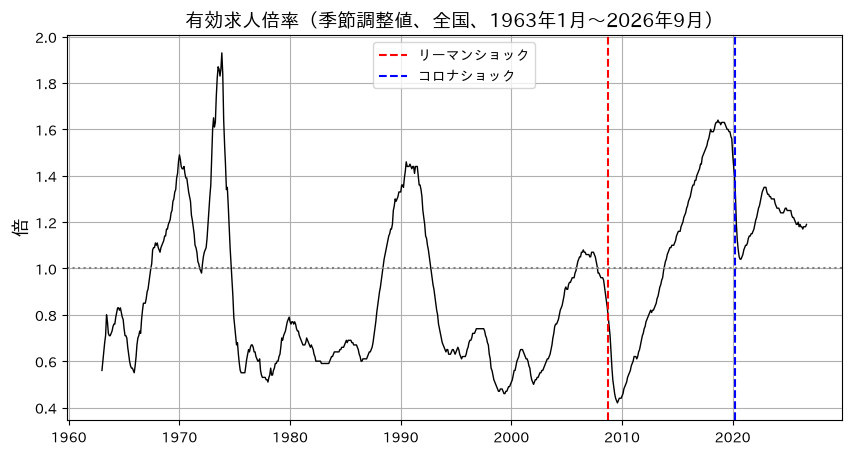

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(df_job['時点'], df_job['有効求人倍率'], color='k', linewidth=1)
plt.axhline(y=1, color='gray', linestyle=':')   # [1] 1 倍の線
plt.axvline(x=pd.Timestamp('2008-09-15'), color='r', linestyle='--', label='リーマンショック')
plt.axvline(x=pd.Timestamp('2020-03-01'), color='b', linestyle='--', label='コロナショック')
plt.title('有効求人倍率（季節調整値、全国、1963年1月〜2026年9月）', fontsize=14)
plt.ylabel('倍', fontsize=14)
plt.legend()
plt.grid()
plt.show()

- [1] `axhline` は横の線（第４講）。`axvline` は縦の線
- 期間を絞るときは、AQ-3 と同じように書く

141 か月


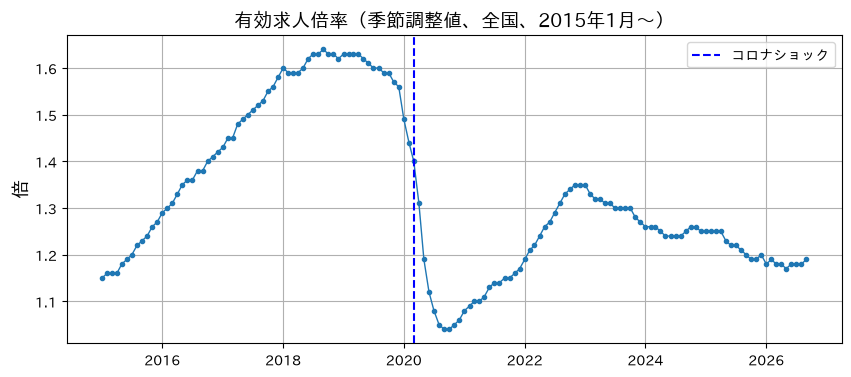

In [13]:
df_job2 = df_job[df_job['時点'] >= '2015-01-01']   # 2015年1月から
print(len(df_job2), 'か月')

plt.figure(figsize=(10, 4))
plt.plot(df_job2['時点'], df_job2['有効求人倍率'], marker='.', linewidth=1)
plt.axvline(x=pd.Timestamp('2020-03-01'), color='b', linestyle='--', label='コロナショック')
plt.title('有効求人倍率（季節調整値、全国、2015年1月〜）', fontsize=14)
plt.ylabel('倍', fontsize=14)
plt.legend()
plt.grid()
plt.show()

**[7] グラフから読み取れることを言葉で書く**（マークダウンのセルに1〜2文）

例：
- 有効求人倍率がいちばん高かったのは1973年11月の 1.93 倍、いちばん低かったのはリーマンショックの後の2009年8月の 0.42 倍だった。2008年9月の 0.83 倍から、1年たたずに半分ほどになった
- 2010年からは上がり続け、2018年9月には 1.64 倍になった。2020年はコロナショックで、1月の 1.49 倍から9月の 1.04 倍まで下がったが、1 倍は下回らなかった

書き方のこつ：
- 「いつ」「どのくらい」を、グラフの目盛か表の数字で書く。いちばん低い月は、次の2行で絞ると分かる

```python
low = df_job['有効求人倍率'].min()     # いちばん低い値
df_job[df_job['有効求人倍率'] == low]   # その値の行（いつのことか）
```

- 理由は推測でよいが、「〜と考えられる」と書く。グラフだけでは原因までは分からない

### CSV を read_csv で読んだとき（format=）

- Excel を通さずに `pd.read_csv` で CSV を読むと、`時点` は文字の `1963年1月` のまま。`pd.to_datetime` にそのまま渡すと `DateParseError`（AQ-6）
- `format=` で、日付の書き方を教える

In [14]:
df_e = pd.DataFrame({'年月': ['2020年1月', '2020年2月', '2020年12月'], '値': [100, 120, 90]})   # [1]
df_e['年月'] = pd.to_datetime(df_e['年月'], format='%Y年%m月')   # [2]
print(df_e.dtypes)
df_e

年月    datetime64[us]
値              int64
dtype: object


,年月,値
0,2020-01-01,100
1,2020-02-01,120
2,2020-12-01,90


- [1] 例として、`read_csv` で読んだときと同じ形の表を作った
- [2] `%Y` は4けたの年、`%m` は月。`'%Y年%m月'` で「○年○月」の形だと教える。`1月` も `12月` も読める
- 年月日なら `format='%Y年%m月%d日'`。日付は、その月の1日になる

▶ **演習**：`ts_描画基礎005`

### 時系列のデータの探し方

自分で選んだデータで時系列のグラフを描くときは、月ごとのデータがある次のサイトから探す。

- [統計ダッシュボード 時系列表](https://dashboard.e-stat.go.jp/timeSeries)：分野 → 系列名を選び、［ダウンロード］で CSV。有効求人倍率・完全失業率・消費者物価指数など
    - 見出しは1行だけ。取ってから描くまでの手順は上の [1]〜[7]。Excel で保存する前に、年月の列の表示の形を `2012/3/14` の形の日付に直す（直さないと `23012` のような数字で読まれる）。値の列名（`（季節調整値）有効求人倍率【倍】` など）は、かっこや記号のない短い名前に直す
- [気象庁 過去の気象データ・ダウンロード](https://www.data.jma.go.jp/risk/obsdl/index.php)：地点・「月別値」・項目（平均気温など）・期間を選んで CSV
    - 年月は `2023/1` の形で、そのまま `pd.to_datetime` で読める。先に、5行目に「品質情報」「均質番号」とある列を消す。そのあと、上の5行のうち項目名の行（`年月,平均気温(℃),…`）だけ残して列名にし、ほかの4行を消す。列名 `平均気温(℃)` は `平均気温` に直す
- どちらも CSV をダウンロードしたら、Excel で開いて xlsx で保存し直す


## AQ-5 日付の引き算と、今の日時（時間があれば）

- 日付どうしを引き算すると、**間の日数**が求まる。`.days` で日数の数字を取り出す
- 日付に `pd.Timedelta(days=100)` を足すと、**100日後の日付**になる
- `pd.Timestamp.today()` は今日の日付（今の時刻つき）。`.normalize()` で時刻を0時にそろえてから引き算する

In [15]:
today = pd.Timestamp.today().normalize()   # [1] 今日（時刻を0時にそろえる）
founded = pd.Timestamp('2017-04-01')        # [2] 創生学部ができた日
newyear = pd.Timestamp('2027-01-01')        # [2] 元日

print(f'今日は {today:%Y年%m月%d日} です')
print(f'創生学部ができてから {(today - founded).days:,} 日たちました')   # [3] 引き算して .days
print(f'元日まで、あと {(newyear - today).days} 日です')
print(f'今日から100日後は {today + pd.Timedelta(days=100):%Y年%m月%d日} です')


今日は 2026年11月21日 です
創生学部ができてから 3,521 日たちました
元日まで、あと 41 日です
今日から100日後は 2027年03月01日 です


- `{(today - founded).days:,}` の `:,` は3けたごとにカンマを付ける。`{today:%Y年%m月%d日}` は日付の書き方を決める f 文字列の書式（`%Y` 年、`%m` 月、`%d` 日）
- 実行した日によって、結果の数字が変わる
- 自分の誕生日を `founded` に入れると、生まれてから何日たったかが分かる



### 今の日時を使う（datetime）

- Python に最初から入っている **datetime** を使うと、プログラムを動かした**今の日時**が分かる（上の `pd.Timestamp.today()` と同じ働き。ネットの例では、こちらがよく使われる）
- `from datetime import datetime` と書いておくと、`datetime.today()`・`datetime.now()` で今の日時が取れる。2つはほぼ同じ働き（`now()` は時差（タイムゾーン）も指定できる）
- `.year`・`.month`・`.day`・`.hour`・`.minute` で、年・月・日・時・分を**数字で**取り出せる。`.weekday()` は曜日の番号（月曜が 0、日曜が 6）

In [16]:
from datetime import datetime

now = datetime.now()     # [1] 今の日時
print(now)
print(datetime.today())  # [1] today() も同じ

print(now.year, now.month, now.day, now.hour, now.minute)   # [2] 数字で取り出す
print('曜日の番号', now.weekday())                          # [3] 月曜が 0、日曜が 6
print(f'{now:%Y年%m月%d日 %H時%M分}')                        # [4] 書き方を決めて表示

2026-11-21 16:52:35.832374
2026-11-21 16:52:35.832483
2026 11 21 16 52
曜日の番号 5
2026年11月21日 16時52分


- [1] 秒の後ろに、もっと細かい数字（100万分の1秒）まで出る。実行するたびに変わる
- [4] `%H` は時、`%M` は分。書き方は上の `{today:%Y年%m月%d日}` と同じ

### 時刻で動きを変える（if 文、第13講）

- 取り出した数字を if 文の条件に使うと、**動かした時刻で結果が変わる**プログラムが作れる

In [17]:
now = datetime.now()

if now.hour < 12:      # 0時〜11時
    print('おはようございます')
elif now.hour < 18:    # 12時〜17時
    print('こんにちは')
else:                  # 18時〜23時
    print('こんばんは')

こんにちは


### 例：曜日でレアが出やすくなるガチャ

- `np.random.rand()` は、0 以上 1 未満の数をでたらめに1つ作る（第13講）。0.05 より小さくなる確率は 5%
- 金曜日（授業の日）だけ、レアの確率を 30% に上げる

In [18]:
now = datetime.now()

if now.weekday() == 4:   # [1] 金曜日（月曜が 0 なので、金曜は 4）
    rare = 0.3
else:
    rare = 0.05

r = np.random.rand()     # [2] 0 以上 1 未満のでたらめな数
if r < rare:             # [3] rare より小さければ当たり
    print('★★★ レア！')
else:
    print('★ ノーマル')
print(f'今日のレアの確率は {rare * 100:.0f}%')

★★★ レア！
今日のレアの確率は 5%


- 何回か実行してみよう。結果は実行するたびに変わる
- 変えてみよう：`now.weekday() == 4` を `now.hour >= 12`（午後だけ確率アップ）や `now.month == 12`（12月だけ）に変える。`rare` の値を変える
- 10回まとめて引くなら、for 文（第12講）を使い、`for k in range(10):` の中に [2] と [3] を入れる

### 例：生まれたときから積み立てたら（今日に線を引く）

- 今の1年生が生まれた月（2007年10月とする）から、親が毎月1万円を40年間積み立てたときの推移を、年率を変えて比べる
- **for 文**（第12講 U-1）と、**リストの append**（第12講 U-5「くり返しでリストを作る」）を使う例。外の for で年率を1つずつ変え、中の for で1か月ずつ額を計算して `values.append(…)` でリストにためる
- `pd.date_range(始まり, periods=個数, freq='MS')` は、月の初めの日付を並べて作る（`'MS'` は Month Start）。40年分なので `40 * 12` 個
- 毎月、それまでの額に1か月分の利息（年率 ÷ 12）を付けてから、1万円を足す。利息にも利息が付く（**複利**）
- `datetime.today()` の位置に `axvline` で縦線を引くと、「今どこにいるか」が分かる

年率 0%：今日 230 万円、40年後 480 万円
年率 1%：今日 253 万円、40年後 590 万円
年率 3%：今日 310 万円、40年後 926 万円
年率 5%：今日 385 万円、40年後 1526 万円
年率 8%：今日 542 万円、40年後 3491 万円


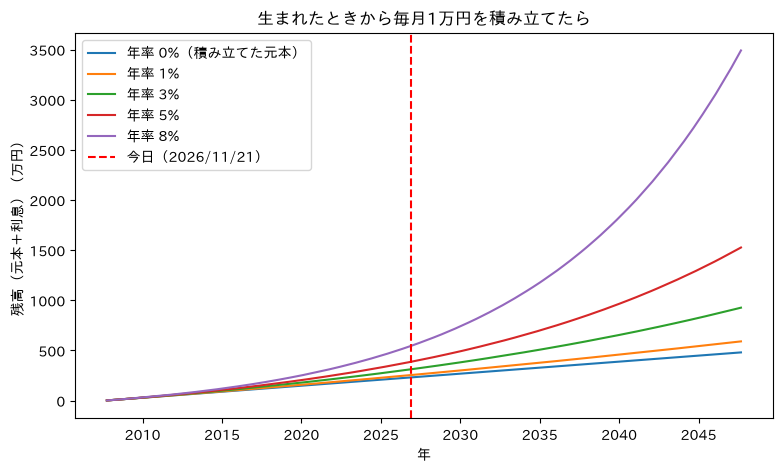

In [19]:
birth = pd.Timestamp('2007-10-01')                           # [1] 生まれた月（今の1年生）
months = pd.date_range(birth, periods=40 * 12, freq='MS')    # [2] 40年分の月の初め
today = datetime.today()

plt.figure(figsize=(9, 5))
for rate in [0, 0.01, 0.03, 0.05, 0.08]:                     # [3] 年率
    total = 0
    values = []
    for m in months:
        total = total * (1 + rate / 12) + 10000              # [4] 1か月分の利息を足して、1万円を積む
        values.append(total / 10000)
    values = np.array(values)
    now = values[months <= today][-1]
    print(f'年率 {rate:.0%}：今日 {now:.0f} 万円、40年後 {values[-1]:.0f} 万円')
    name = f'年率 {rate:.0%}'
    if rate == 0:
        name = name + '（積み立てた元本）'                     # [5] 0% は元本の累計
    plt.plot(months, values, label=name)

plt.axvline(x=today, color='r', linestyle='--', label=f'今日（{today:%Y/%m/%d}）')   # [6] 今日の線
plt.title('生まれたときから毎月1万円を積み立てたら')
plt.xlabel('年')
plt.ylabel('残高（元本＋利息）（万円）')                       # [7] 利息も含む
plt.legend()
plt.show()

- [3] `{rate:.0%}` は、0.03 を `3%` と書く f 文字列の書式。年率の目安は下の「参考」の表
- `values[months <= today][-1]` は、今日までの月だけ取り出した最後（いちばん新しい月）の額
- 年率 0% の線は利息が付かないので、**積み立てたお金の累計（元本）**そのもの（1万円 × 月数）。40年後は 480 万円
- [5] そこで凡例を「年率 0%（積み立てた元本）」にした。[7] ほかの線は利息も含むので、縦軸は「残高（元本＋利息）」
- ほかの線と 0% の線の差が、利息で増えた分。年率 8% だと40年後は約 3500 万円で、元本の約7倍になる。今日の線より右で差が大きく開く
- 変えてみよう：`birth` を自分の生まれた月に、`10000` を毎月の額に、`[0, 0.01, 0.03, 0.05, 0.08]` の年率を下の表の値に変える

**参考：主な指標の年率（2026年11月ごろに調べた値。時期や集計する年数で変わる）**

| 指標 | 年率 | 集計した年数 |
|---|---|---|
| 普通預金の金利（メガバンク） | 0.5% | 2026年11月からの金利 |
| 消費者物価の上昇率 | 2.3% | 1年（2026年10月の前年同月比） |
| 長期金利（10年国債の利回り） | 約 2.6〜3% | 2026年秋に買って10年持つ場合 |
| 日経平均（配当なし） | 約 3.6% | 30年（〜2026年5月末） |
| GPIF（年金の積立金。国内外の株と債券に分けて運用） | 約 4.95% | 25年（2001年度〜2026年度4〜6月） |
| TOPIX（東証の株全体、配当込み） | 約 5% | 30年（〜2026年9月末） |
| 先進国の株（MSCI World、配当込み、ドルで計算） | 約 8.1% | 30年（〜2026年6月末） |
| S&P500（アメリカの株、配当込み、円で計算） | 約 11% | 30年（〜2026年10月末） |

- 株の年率は、集計する年数で大きく変わる。例えば過去20年だと TOPIX は約 7.1%、S&P500 は約 12.4%。過去10年だと日経平均は約 14%、S&P500 は約 20%。年によっては大きく減る
- 年率が物価の上昇率より低いと、額は増えても、そのお金で買えるものは減っていく
- 税金や手数料は考えていない


## AQ-6 よくあるトラブル

| 困ったこと・エラーの最後の行 | 原因 | 直し方 |
|---|---|---|
| 横軸の日付がつぶれて黒い帯になる、間隔がおかしい | `Date` が文字（`object`）のまま | `pd.to_datetime` で日付の型にする（AQ-1）。`df.info()` で確かめる |
| 日付の列が `23012` や `43831` のような5けたの数字（`int64`）になっている | Excel の日付の中身（シリアル値。1900年1月1日からの日数）のまま読まれた。表示が `2020年1月` の形の日付で起きる（統計ダッシュボードの CSV を Excel で開いて保存したときなど） | Excel でその列を選び、セルの書式設定で `2012/3/14` の形の日付にして保存し直す（AQ-4） |
| `DateParseError: Unknown datetime string format` | `2020年1月`（CSV を `read_csv` で読んだとき）や `令和2年1月` など、`to_datetime` が読めない書き方の文字 | `format='%Y年%m月'` を付ける（AQ-4）か、Excel で `2020/1/1` の形の日付に直す |
| `TypeError: unsupported operand type(s) for &` | 2つの条件をかっこで囲んでいない | `(条件1) & (条件2)` と書く（AQ-3） |
| `ValueError: The truth value of a Series is ambiguous` | 2つの条件を `and` でつないだ | `and` ではなく `&` を使う（AQ-3） |
| `TypeError: Invalid comparison between dtype=datetime64… and date` | ネット記事の `date(…)`（`datetime.date(…)`）と比べた | `pd.Timestamp('2020-01-01')` で書く（下の参考） |
| `AttributeError: module 'datetime' has no attribute 'now'` | `import datetime` と書いた | `from datetime import datetime` と書く（AQ-5） |
| 横軸の文字が重なる | 目盛の文字が長い | `plt.xticks(rotation=45)` |

## 参考：ネット記事でよく見る datetime の書き方

- AQ-5 で使った datetime は、日付を1つ作ったり、日数を足したりもできる。ネットの記事ではこちらの書き方がよく出てくるので、pandas の書き方との対応を知っておく

| datetime（`from datetime import datetime, date, timedelta`） | pandas |
|---|---|
| `datetime(2020, 1, 1)` | `pd.Timestamp('2020-01-01')` |
| `datetime.now()`、`datetime.today()`、`date.today()`（日付だけ） | `pd.Timestamp.now()`、`pd.Timestamp.today()` |
| `timedelta(days=10)` | `pd.Timedelta(days=10)` |
| `d.strftime('%Y/%m/%d')` | 同じ書き方が使える |

- 表の日付の列と比べるとき、`datetime(…)` は比べられるが、`date(…)`（日付だけ）は**エラーになる**。写したコードで困ったら、`pd.Timestamp(…)` で包む
- ネットの記事には、`import datetime` と書いて `datetime.datetime.now()` とする書き方もある。`import datetime` のあとで `datetime.now()` と書くとエラーになる（AQ-6）
- `locale.setlocale(…)` や、月を0なしで表示する `%#m`・`%-m` は、Windows と Mac で書き方が違う（片方ではエラーになる）。この授業では使わない


In [20]:
from datetime import datetime, date

print((df_dji['Date'] >= datetime(2020, 1, 1)).sum(), '週')   # これは動く
# df_dji[df_dji['Date'] >= date(2020, 1, 1)]                 # これは TypeError になる
print(pd.Timestamp(date(2020, 1, 1)))                          # pd.Timestamp で包めば pandas の日付になる


354 週
2020-01-01 00:00:00


---
# AS. 発展（できる人だけ）

## AS-1 移動平均

- 時系列は細かく上下するので、**移動平均**（直近の何個かの平均）でならすと傾向が見やすい
- `df['列名'].rolling(52).mean()`：直近52週（約1年）の平均

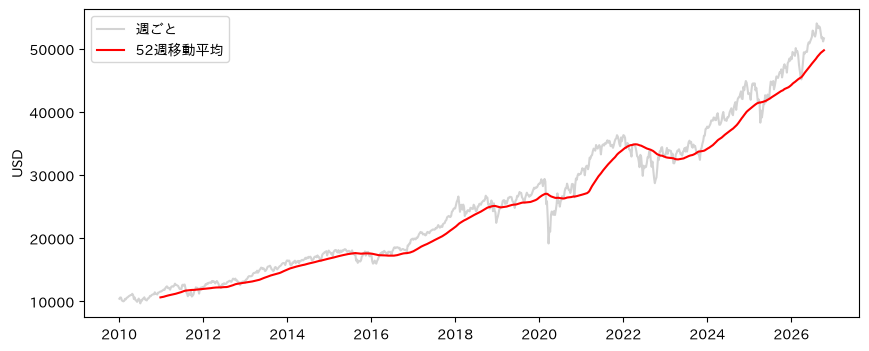

In [21]:
df_recent = df_dji[df_dji['Date'] >= '2010-01-01']
ma = df_recent['Close'].rolling(52).mean()

plt.figure(figsize=(10, 4))
plt.plot(df_recent['Date'], df_recent['Close'], color='lightgray', label='週ごと')
plt.plot(df_recent['Date'], ma, color='r', label='52週移動平均')
plt.ylabel('USD')
plt.legend()
plt.show()

- 最初の51週は平均が計算できないので、線が始まらない

## AS-2 日付の目盛の書き方を決める

- 横軸の日付の目盛は自動で決まる。間隔や書き方を自分で決めるときは、`matplotlib.dates`（`mdates`）を使う
- `plt.gca()` は「今のグラフ」（第８講）。`.xaxis` はその横軸
- `set_major_locator` で目盛の**間隔**、`set_major_formatter` で目盛の**書き方**を決める

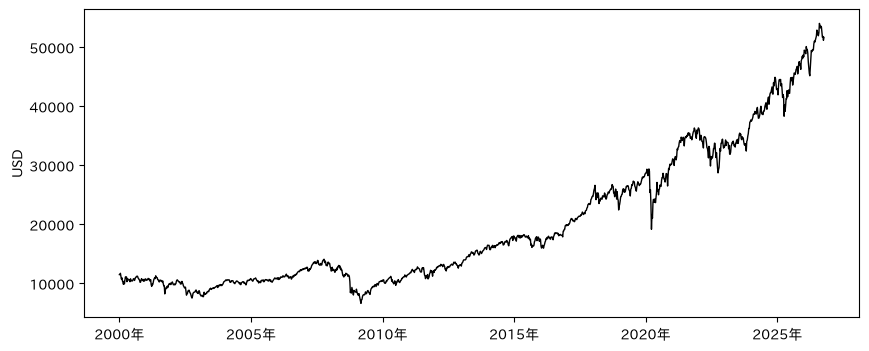

In [22]:
import matplotlib.dates as mdates

df_recent = df_dji[df_dji['Date'] >= '2000-01-01']

plt.figure(figsize=(10, 4))
plt.plot(df_recent['Date'], df_recent['Close'], color='k', linewidth=1)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(5))           # [1] 5年ごとに目盛
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y年'))  # [2] 「2000年」の形で書く
plt.ylabel('USD')
plt.show()


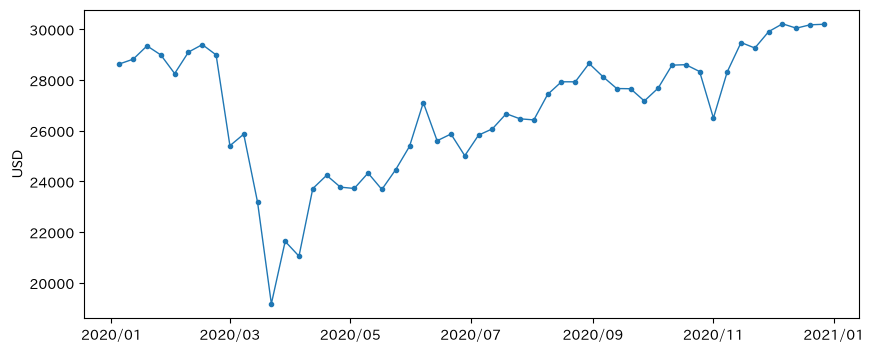

In [23]:
df_2020 = df_dji[(df_dji['Date'] >= '2020-01-01') & (df_dji['Date'] < '2021-01-01')]

plt.figure(figsize=(10, 4))
plt.plot(df_2020['Date'], df_2020['Close'], marker='.', linewidth=1)
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))  # [1] 2か月ごとに目盛
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y/%m'))  # [2] 「2020/03」の形で書く
plt.ylabel('USD')
plt.show()


| 間隔 | 書き方 |
|---|---|
| 年ごと | `mdates.YearLocator(5)`（5年ごと） |
| 月ごと | `mdates.MonthLocator(interval=2)`（2か月ごと） |
| 日ごと | `mdates.DayLocator(interval=7)`（7日ごと） |

- 書き方の記号：`%Y` 年（4けた）、`%y` 年（下2けた）、`%m` 月、`%d` 日。`'%Y年%m月'` のように文字を混ぜてよい
- 月の `03` の0を取る `%#m`（Windows）・`%-m`（Mac）は OS で違うので、使わない

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| 日付の型にする | `df['Date'] = pd.to_datetime(df['Date'])` |
| 時系列のグラフ | `plt.plot(df['Date'], df['列名'])` |
| 日付の位置・期間 | `pd.Timestamp('2020-03-01')`、`plt.xlim(開始, 終わり)` |
| Excel の日付が数字（`int64`）で読まれる | Excel で表示の形を `2012/3/14` の形の日付にして保存し直す（AQ-4） |
| 期間でデータを絞る | `df[df['Date'] >= '2020-01-01']` |
| 2つの条件で絞る | `df[(条件1) & (条件2)]`（かっこで囲む。`and` は使わない） |
| 日付の引き算 | `(pd.Timestamp('2027-01-01') - pd.Timestamp('2017-04-01')).days` |
| 今の日時 | `from datetime import datetime` → `now = datetime.now()`、`now.hour`・`now.weekday()` |
| 目盛の文字を斜めに | `plt.xticks(rotation=45)` |

15回おつかれさまでした。ここまでの notebook は、グラフを描くときの**ひな形集**として使える。困ったら第11講の「グラフの型の一覧」から探す。